In [101]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from aostools.climate import PlotEPfluxArrows

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

import numpy as np

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    ds_djf['time'] = pd.date_range(str(ds_djf.time[0].values).split('-')[0], str(int(str(ds_djf.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    return ds_djf


def anomaly_calculation(model, clim):
    ano_list = []
    for i in range(1,13):
        ano_list.append(model.sel(time=model.time[model.time.dt.month.isin(i)]) - clim.sel(month=i))
    return xr.concat(ano_list, dim='time').sortby('time')


def load_climatology(path):
    clim = xr.open_dataset(glob.glob(path)[0])
    clim['time'] = [1,2,3,4,5,6,7,8,9,10,11,12]
    clim = clim.rename({'time': 'month'})
    return clim

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data

def pressure_weighting(data, plevs=slice(7000,2000)):
    # here I select the pressure level intervall 
    # for which I want to caluculate the layer weights
    # (in this case plevs = 70 - 20 hPa)
    data = data.sel(plev=plevs)
    # Then natural logarithm of this pressure values is caluculated
    log_pressure = np.log(data.plev.values)  
    # the difference between this logaritmic pressure values is made
    log_layer_thickness = np.abs(np.diff(log_pressure))
    # then i devide these differences by the total thickness of the layer
    # = sum of the differences
    log_layer_thickness = log_layer_thickness / sum(log_layer_thickness)

    # this part just creates an array to make it compatible with the data 
    # #(no manipulation of the results done in this step)
    log_layer_thickness = xr.DataArray(
        log_layer_thickness,
        coords={"plev": data.plev.values[:-1]},  # Assign to the lower pressure level of each layer
        dims=["plev"]
    )

    # finally I multiply the data with the "normalized" thickness of the pressure layer
    data = data * log_layer_thickness

    return data.sum(dim='plev')

In [149]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/epflux/'

enso_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])

# calculation for piControl
model = models[1]
epfz_clim_pi = load_climatology(path_piControl + model + '/epfz_clim_EmonZ*')
epfy_clim_pi = load_climatology(path_piControl + model + '/epfy_clim_EmonZ*')

epfz_tmp = xr.open_dataset(glob.glob(path_piControl + model + '/epfz_EmonZ*.nc')[0], decode_times=time_coder)
# epfz_ano = anomaly_calculation(epfz_tmp, epfz_clim_pi)
# epfz_piControl = calculate_djf_mean(epfz_ano)
epfz_piControl = calculate_djf_mean(epfz_tmp)

epfy_tmp = xr.open_dataset(glob.glob(path_piControl + model + '/epfy_EmonZ*.nc')[0], decode_times=time_coder)
# epfy_ano = anomaly_calculation(epfy_tmp, epfy_clim_pi)
# epfy_piControl = calculate_djf_mean(epfy_ano)
epfy_piControl = calculate_djf_mean(epfy_tmp)

enso_nao_flags = enso_nao_flags.loc[model]


volc_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_change.csv')
volc_nao_flags = volc_nao_flags.set_index(['model', 'realization'])
df_volc = volc_nao_flags.where(volc_nao_flags.experiment=='volc').dropna().drop('experiment', axis=1)

epfz_volc = load_data(path + model + '/epfz_EmonZ_*fixed_dates.nc')
epfy_volc = load_data(path + model + '/epfy_EmonZ_*fixed_dates.nc')

epfz_clim_pi = load_climatology(path_piControl + model + '/epfz_clim_EmonZ*')
epfy_clim_pi = load_climatology(path_piControl + model + '/epfy_clim_EmonZ*')

# epfz_ano = anomaly_calculation(epfz_volc['epfz'], epfz_clim_pi['epfz'])
# epfz_volc = calculate_djf_mean(epfz_ano)
epfz_volc = calculate_djf_mean(epfz_volc.epfz)

# epfy_ano = anomaly_calculation(epfy_volc['epfy'], epfy_clim_pi['epfy'])
# epfy_volc = calculate_djf_mean(epfy_ano)
epfy_volc = calculate_djf_mean(epfy_volc.epfy)

df_volc = df_volc.loc[model]

/tmp/ipykernel_2186787/3700192644.py:28: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_2186787/3700192644.py:28: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_2186787/3700192644.py:38: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds.append(x

In [143]:
epfz_piControl = epfz_piControl.sel(plev=slice(100000,1000))
epfy_piControl = epfy_piControl.sel(plev=slice(100000,1000))

epfy_volc = epfy_volc.sel(plev=slice(100000,1000))
epfz_volc = epfz_volc.sel(plev=slice(100000,1000))

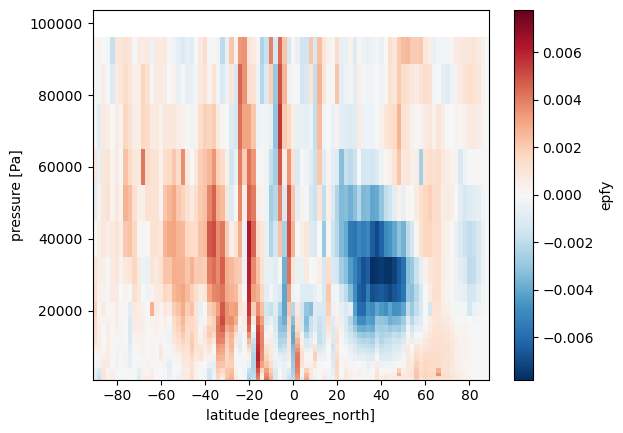

In [148]:
epfy_piControl.mean('time').epfy.plot()#.sel(plev=slice(100000,1000), month=1).epfy.plot()

ValueError: X and Y must be the same size, but X.size is 90 and Y.size is 39.

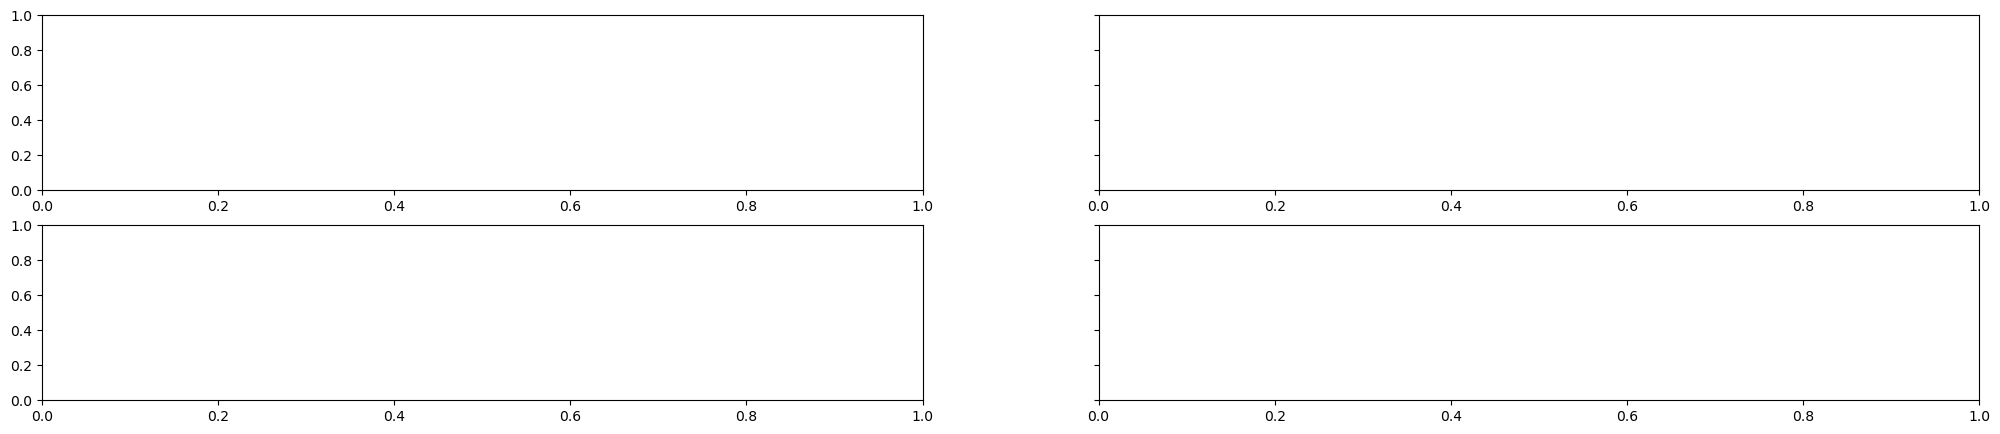

In [125]:
fig, axs = plt.subplots(2,2,figsize=(25,5), sharey=True)
naopz = epfz_piControl.epfz.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).mean('time')
naopy = epfy_piControl.epfy.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).mean('time')
naonz = epfz_piControl.epfz.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).mean('time')
naony = epfy_piControl.epfy.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).mean('time')

#PlotEPfluxArrows(naopy.lat, naopy.plev, naopy, naopz, fig=fig, ax=axs[0,0], yscale='log')#, scale=1e22)
#PlotEPfluxArrows(naonz.lat, naonz.plev, naony, naonz, fig=fig, ax=axs[0,1], yscale='log')#, scale=1e22)

naopz = epfz_volc.sel(ens=df_volc.where(df_volc.nao_flag == 1).dropna().index).sel(time='1992-02').squeeze().mean('ens')
naopy = epfy_volc.sel(ens=df_volc.where(df_volc.nao_flag == 1).dropna().index).sel(time='1992-02').squeeze().mean('ens')
naonz = epfz_volc.sel(ens=df_volc.where(df_volc.nao_flag == -1).dropna().index).sel(time='1992-02').squeeze().mean('ens')
naony = epfy_volc.sel(ens=df_volc.where(df_volc.nao_flag == -1).dropna().index).sel(time='1992-02').squeeze().mean('ens')

PlotEPfluxArrows(naopz.lat, naopz.plev, naopy, naopz, fig=fig, ax=axs[1,0], yscale='log')#, scale=1e22)
PlotEPfluxArrows(naonz.lat, naonz.plev, naony, naonz, fig=fig, ax=axs[1,1], yscale='log')#, scale=1e22)



axs[0,0].set_title('NAO+')
axs[0,1].set_title('NAO-')
axs[0,0].set_ylabel('piControl')
axs[1,0].set_ylabel('Volcanic')
plt.suptitle(model + ' - DJF 1992 - efplux anomlies')

# plt.savefig(plotdir + model + '_epflux_absolutevalues.png', dpi=200)
plt.savefig(plotdir + model + '_epflux_anomlies.png', dpi=200)

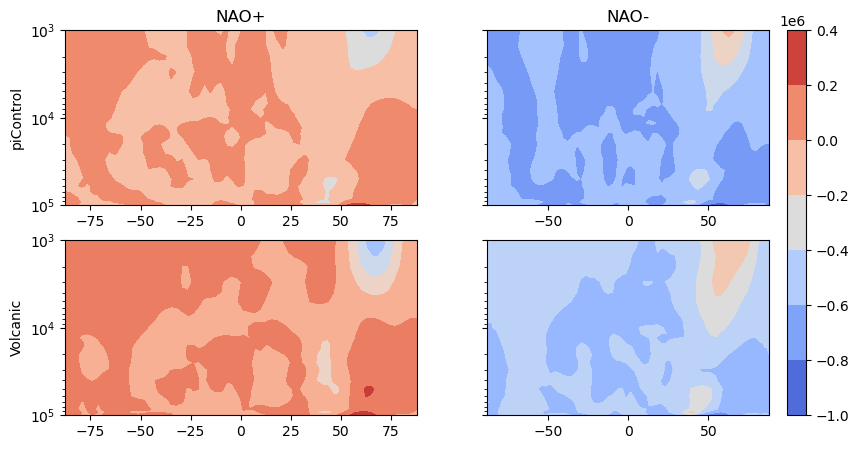

In [6]:
fig, axs = plt.subplots(2,2,figsize=(10,5), sharey=True)

naop = epfz_piControl.epfz.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).mean('time')
cbar = axs[0,0].contourf(naop.lat, naop.plev, naop, cmap='coolwarm')
naon = epfz_piControl.epfz.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).mean('time')
axs[0,1].contourf(naon.lat, naon.plev, naon, cmap='coolwarm')

naop = epfz_volc.sel(ens=df_volc.where(df_volc.nao_flag == 1).dropna().index).sel(time='1992-02').squeeze().mean('ens')
axs[1,0].contourf(naop.lat, naop.plev, naop, cmap='coolwarm')
naon = epfz_volc.sel(ens=df_volc.where(df_volc.nao_flag == -1).dropna().index).sel(time='1992-02').squeeze().mean('ens')
axs[1,1].contourf(naon.lat, naon.plev, naon, cmap='coolwarm')

# axs[0,0].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])
# axs[1,0].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])
# axs[0,1].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])
# axs[1,1].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])

axs[0,0].set_title('NAO+')
axs[0,1].set_title('NAO-')
axs[0,0].set_ylabel('piControl')
axs[1,0].set_ylabel('Volcanic')
axs[0,0].set_ylim(100000, 1000)
axs[0,0].set_yscale('log')

#plt.suptitle(model + ' - DJF 1992 - w term')
plt.colorbar(cbar, ax=axs[0:2,1])
#plt.savefig(plotdir + model + '_wtem_contour.png', dpi=200)

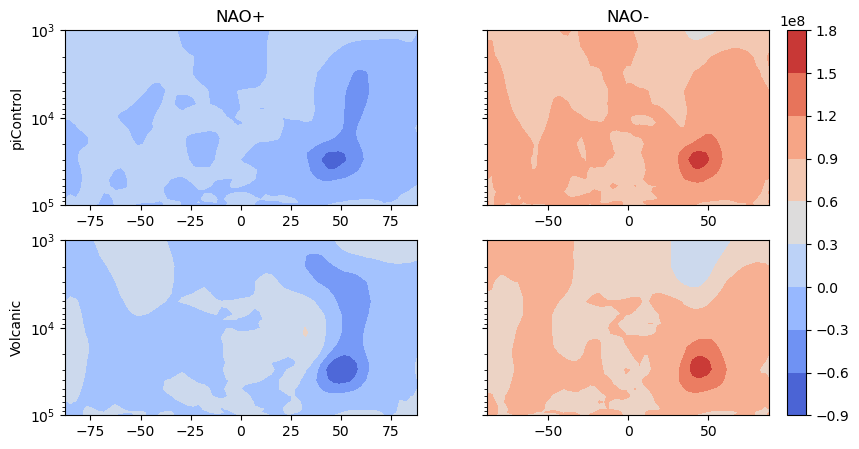

In [7]:
fig, axs = plt.subplots(2,2,figsize=(10,5), sharey=True)

naop = epfy_piControl.epfy.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == 1).dropna().year.values).mean('time')
cbar = axs[0,0].contourf(naop.lat, naop.plev, naop, cmap='coolwarm')
naon = epfy_piControl.epfy.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag == -1).dropna().year.values).mean('time')
axs[0,1].contourf(naon.lat, naon.plev, naon, cmap='coolwarm')

naop = epfy_volc.sel(ens=df_volc.where(df_volc.nao_flag == 1).dropna().index).sel(time='1992-02').squeeze().mean('ens')
axs[1,0].contourf(naop.lat, naop.plev, naop, cmap='coolwarm')
naon = epfy_volc.sel(ens=df_volc.where(df_volc.nao_flag == -1).dropna().index).sel(time='1992-02').squeeze().mean('ens')
axs[1,1].contourf(naon.lat, naon.plev, naon, cmap='coolwarm')

# axs[0,0].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])
# axs[1,0].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])
# axs[0,1].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])
# axs[1,1].vlines([60, 80], 1000, 10000, color='k', linestyle=['--', '--', '-.'])

axs[0,0].set_title('NAO+')
axs[0,1].set_title('NAO-')
axs[0,0].set_ylabel('piControl')
axs[1,0].set_ylabel('Volcanic')
axs[0,0].set_ylim(100000, 1000)
axs[0,0].set_yscale('log')

#plt.suptitle(model + ' - DJF 1992 - w term')
plt.colorbar(cbar, ax=axs[0:2,1])
#plt.savefig(plotdir + model + '_wtem_contour.png', dpi=200)